# DATA-445: In-Class Assignment 20
---

## 1. Customer Segmentation

Consider the `customers.csv` datafile. This file contains information related to customers' activity on a company website. Below are the description of the variables.

- **ID:** customer ID
- **Visit_Time:** The number of visits to the company's website in a given month.
- **Average_Expense:** The average amount of money that the customer has spend.
- **Sex:** gender of the customer (0: female, 1: male).
- **Age:** age of the customer.

**In Python**, answer the following:

### (a) (3 points) 
Using the `pandas` library, read the csv file and create a data-frame called `customers`.

In [1]:
import pandas as pd

customers = pd.read_csv("customers.csv")
customers.head()

,ID,Visit_Time,Average_Expense,Sex,Age
0,1,3,5.7,0,10
1,2,5,14.5,0,27
2,3,16,33.5,0,32
3,4,5,15.9,0,30
4,5,16,24.9,0,23


### (b) (3 points) 
Using the appropriate Python commands, remove the `ID` variable.

In [2]:
customers = customers.drop(columns="ID", axis=1)
customers.head()

,Visit_Time,Average_Expense,Sex,Age
0,3,5.7,0,10
1,5,14.5,0,27
2,16,33.5,0,32
3,5,15.9,0,30
4,16,24.9,0,23


### (c) (8 points) 
Instead of using the principal components to visualize potential groupings, apply $t$-SNE to the (scaled) data and project it onto two dimensions. Visualize the resulting embedding with a scatterplot. Based on this visualization, how many groups (clusters) would you estimate are present in this dataset?

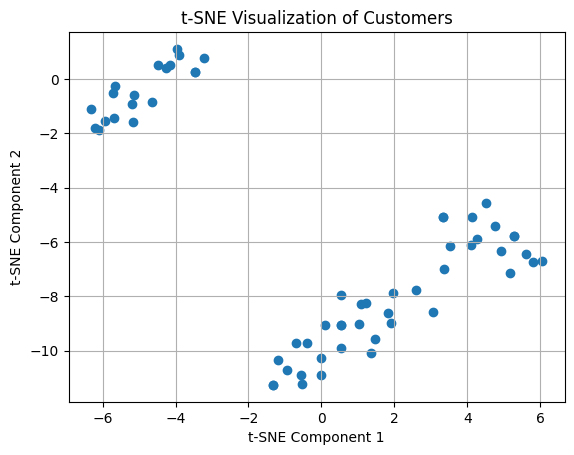

In [3]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.manifold import TSNE

scaler = MinMaxScaler()
customers_scaled = scaler.fit_transform(customers)

# Define and fit t-SNE
tsne = TSNE(n_components=2, 
            perplexity=20, 
            learning_rate='auto', 
            init="pca", 
            random_state=42)
customers_tsne = tsne.fit_transform(customers_scaled)

# Visualizing t-SNE results
import matplotlib.pyplot as plt

plt.scatter(customers_tsne[:, 0], customers_tsne[:, 1])
plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.title("t-SNE Visualization of Customers")
plt.grid(True)
plt.show();

## 2. Heart Disease Classification: UMAP for Feature Engineering

Consider the `framingham.csv` data file described in previous in class assignments. Recall that the classification goal is to predict whether a patient has a 10-year risk of future coronary heart disease (`TenYearCHD`).

In **Python**, answer the following:

### (a) (4 points) 
Using the `pandas` library, read the csv data file and create a data-frame called `heart`. Remove the missing values.

In [4]:
import pandas as pd 

heart = pd.read_csv("framingham.csv")
heart = heart.dropna()
heart.head()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


### (b) (10 points) 
Using `age`, `currentSmoker`, `totChol`, `BMI`, and `heartRate` as the predictor variables, and `TenYearCHD` as the target variable, set up a `StratifiedKFold` with 10 folds (taking into account the proportion of 0s and 1s). Using the original predictors (no feature engineering), train a `LogisticRegression` model and use the area under the ROC-AUC curve as a measure of performance. Make sure to use the `cross_val_score` function with your `StratifiedKFold` object. This is your **baseline** out-of-sample performance.

In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline

X = heart[["age", "currentSmoker", "totChol", "BMI", "heartRate"]]
y = heart["TenYearCHD"]

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

In [6]:
from sklearn.linear_model import LogisticRegression

# Define the logistic regression pipeline
logit_md = Pipeline([
    ("scaler", StandardScaler()),
    ("logit", LogisticRegression(max_iter=1000, random_state=42))
])

# Evaluate the logistic regression model using cross-validation
logit_scores = cross_val_score(logit_md, X, y, cv=skf, scoring="roc_auc", n_jobs=-1)
print("Cross-validated ROC AUC:", logit_scores.mean())

Cross-validated ROC AUC: 0.6995697799434097


### (c) (12 points) 
Use `UMAP` as a feature engineering step: build a `Pipeline` that first standardizes the predictor variables (e.g., using `StandardScaler`), then applies `UMAP` to the standardized variables (e.g., 2 components), and then trains a `LogisticRegression` model on the resulting embedding. Using the **same** `StratifiedKFold` object from part (b), compute the cross-validated area under the ROC-AUC curve with `cross_val_score`. Fitting `StandardScaler` and `UMAP` inside the pipeline ensures that both are re-fit on only the training fold each time, so the test fold remains truly out-of-sample.

In [ ]:
 #pip install umap-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 26.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.5/40.5 MB 31.4 MB/s  0:00:01m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [umap-learn]4 [numba]

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [8]:
from umap import UMAP

# Define the UMAP + Logistic Regression pipeline
umap_model = Pipeline([
    ("scaler", StandardScaler()),
    ("umap", UMAP(random_state=42)), 
    ('logistic', LogisticRegression(max_iter=1000, random_state=42))
])

# Evaluate the UMAP + Logistic Regression model using cross-validation
umap_scores = cross_val_score(umap_model, X, y, cv=skf, scoring="roc_auc", n_jobs=-1)
print("Cross-validated ROC AUC:", umap_scores.mean())

/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the l

Cross-validated ROC AUC: 0.671267466169909


### (d) (4 points) 
Compare the (mean) cross-validated area under the ROC-AUC curve obtained in parts (b) and (c). Based on this comparison, did using `UMAP` as a feature engineering step improve, worsen, or have no meaningful effect on the model's out-of-sample performance?

I will use the original Logistic Regression model because it performed better than UMAP (0.6996 vs. 0.6713).